In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from scipy import stats as sstats
from catboost import CatBoostRegressor, CatBoostClassifier

REPO_ROOT = Path.cwd().parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from egypt_survey_ml.config import DatasetConfig
from egypt_survey_ml.dataset import prepare_dataset

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# --- scenario settings -------------------------------------------------
# Every value below can be changed to test a different scenario. Defaults live in
# src/egypt_survey_ml/config.py (DatasetConfig); anything left out keeps its default
# (rng_seed=42, min_working_age=15, weeks_per_month=365.25/7/12).
cfg = DatasetConfig(
    include_empstab=True,   # see design-decisions table above: circular under the zero-inclusive regime
    include_hrswk=True,     # team decision (Vanni's email) excludes hours for the female model;
                            # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
                            # for female too. Toggle this to test how much of their higher
                            # reported R2 comes from that one feature, holding everything else
                            # (repeated eval, intensive-margin decomposition, wage formula, cap)
                            # fixed at our more rigorous setup.
    zero_handling="drop_random",   # one of: "none", "drop_random", "lognormal_synthetic"
    predict_log_wage=False,
    include_ribasim=True,
    wage_perturbation=False,
    wage_perturbation_sigma=0.03,
    drop_random_frac=1.0,   # only used when zero_handling == "drop_random"
    n_reps=100,             # change this
    male_outlier_cap=5000,
    female_outlier_cap=4000,
    data_filename="data_correlation.xlsx",
)

In [3]:
# Loads the survey, builds household wage context, makes the sex-stratified train/test split and the
# wage target, attaches governorates, and loads the command-area data and feature mask
# (see src/egypt_survey_ml/dataset.py).
ds = prepare_dataset(cfg)

train_pool = ds.train_pool
test_pool = ds.test_pool
survey_columns = ds.survey_columns
excel_df = ds.excel_df
EXCEL_PATH = ds.paths.excel_path

# dataset-bound helpers used by the cells below
assign_command_units = ds.assign_command_units
build_feature_frame = ds.build_feature_frame
apply_zero_handling = ds.apply_zero_handling

data source: OneDrive (/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data)
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS IND-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS HH-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/reg_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/command_area_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/correlation.xlsx
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Re

In [4]:
upper_egypt_govs = ['Aswan', 'Luxor', 'Qena', 'Suhag', 'Asyout', 'Menia', 'Beni- Suef', 'Fayoum', 'Cairo', 'Giza']

In [5]:
from egypt_survey_ml.predict import load_members, predict_ensemble, describe, STAT_NAMES

MODEL_DIR = REPO_ROOT / 'models/hp-tuned'

# One (seed, classifier, regressor) member per command-unit draw; the seeds come from model_metrics.csv
male_members = load_members(MODEL_DIR / 'classifiers-with-hrs', MODEL_DIR / 'regressors-with-hrs-22', 'male')
female_members = load_members(MODEL_DIR / 'classifiers-with-hrs', MODEL_DIR / 'regressors-with-hrs-22', 'female')

male_members_nr = load_members(MODEL_DIR / 'no-ribasim/classifiers-with-hrs', MODEL_DIR / 'no-ribasim/regressors-with-hrs-22', 'male')
female_members_nr = load_members(MODEL_DIR / 'no-ribasim/classifiers-with-hrs', MODEL_DIR / 'no-ribasim/regressors-with-hrs-22', 'female')

In [6]:
# One example draw (seed 0) of the training frame, for exploring the data in the cells below
from egypt_survey_ml.dataset import TARGET_COLS

train_geo = ds.assign_command_units(train_pool, seed=0)
train_frame, _, _ = ds.build_feature_frame(train_geo, sex_code=2)
feature_cols = [c for c in train_frame.columns if c not in TARGET_COLS]

In [7]:
# Every member predicts on the command-unit draw it was trained on (its seed).
# Each model picks its own feature columns, so the with/without RIBASIM models need no extra arguments.
pred_male = predict_ensemble(ds, male_members, 'male')
pred_female = predict_ensemble(ds, female_members, 'female')
pred_male_nr = predict_ensemble(ds, male_members_nr, 'male')
pred_female_nr = predict_ensemble(ds, female_members_nr, 'female')

In [8]:
# female: hard classification at P(paid) >= 0.33; male: predicted wage weighted by P(paid)
r2_scores_female = pred_female.r2_per_member(threshold=0.33)
r2_scores_male = pred_male.r2_per_member()

r2_summary = pd.DataFrame({
    "metric": STAT_NAMES,
    "r2_female": describe(r2_scores_female),
    "r2_male": describe(r2_scores_male),
})

# r2_summary.to_csv('r2_summary_ribasim_with_hrs.csv')

In [9]:
r2_summary

,metric,r2_female,r2_male
0,p5,0.500006,0.327030
1,p10,0.514136,0.337132
2,p20,0.531080,0.351193
3,p30,0.537650,0.359189
4,p40,0.545168,0.366393
5,p45,0.548792,0.368183
6,p50,0.557924,0.371243
7,p55,0.566832,0.372275
8,p60,0.570683,0.373919
9,p70,0.575220,0.377865


In [10]:
r2_scores_female = pred_female_nr.r2_per_member(threshold=0.33)
r2_scores_male = pred_male_nr.r2_per_member()

r2_summary = pd.DataFrame({
    "metric": STAT_NAMES,
    "r2_female": describe(r2_scores_female),
    "r2_male": describe(r2_scores_male),
})

# r2_summary.to_csv('r2_summary_no_ribasim_with_hrs.csv')

In [11]:
r2_summary

,metric,r2_female,r2_male
0,p5,0.515448,0.281128
1,p10,0.524143,0.284541
2,p20,0.534784,0.292006
3,p30,0.541439,0.300326
4,p40,0.548768,0.302659
5,p45,0.551111,0.304188
6,p50,0.553912,0.304700
7,p55,0.555118,0.305551
8,p60,0.557526,0.306278
9,p70,0.562228,0.307312


In [12]:
wage_dict = {}
scenario_predictions = {}
for ribasim_run in ["50", "60", "70", "80", "90", "95"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    scenario_predictions[ribasim_run] = {
        'female': predict_ensemble(ds, female_members, 'female', excel_df=ribasim_excel_df),
        'male': predict_ensemble(ds, male_members, 'male', excel_df=ribasim_excel_df),
    }

    for sex in ['female', 'male']:
        pred = scenario_predictions[ribasim_run][sex]
        wage_dict[f'{sex}_{ribasim_run}'] = describe(pred.final_wage(aggregate="median"), weights=None)

wage_df = pd.DataFrame(wage_dict, index=STAT_NAMES)
wage_df

,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,27.849915,1392.217409,26.948169,1392.925402,28.072853,1324.433480,27.727439,1291.811244,29.395435,1281.269275,27.941707,1296.086381
p10,42.940643,1738.398544,42.547431,1723.025933,41.076955,1707.418774,39.614615,1642.357384,38.820927,1671.844249,37.599519,1741.928118
p20,59.438860,1963.586189,58.920047,1947.181319,55.920816,1938.493662,55.580210,1911.668534,55.797940,1926.147438,53.522012,1964.552566
p30,79.372109,2132.331041,76.457946,2104.601601,74.675459,2082.860016,75.132404,2051.889997,74.086166,2057.709158,69.628674,2089.112495
p40,100.215805,2246.609820,92.207080,2219.773841,89.983001,2201.880396,92.257470,2167.702057,87.946744,2155.328426,82.804109,2173.513859
p45,106.942251,2292.751005,103.346561,2266.260313,101.294783,2242.896688,101.292797,2213.438146,97.623029,2199.428515,93.494928,2211.928292
p50,126.405365,2341.748943,119.291646,2318.755371,117.533384,2295.196096,120.963708,2256.154887,110.962690,2239.934116,104.104841,2248.532330
p55,142.736220,2385.830181,135.849426,2363.943957,134.649014,2354.590737,134.805976,2331.391713,123.631966,2301.100747,119.433057,2295.618267
p60,165.864638,2454.277317,159.676460,2430.946379,158.954447,2407.351768,160.053804,2390.154725,141.259092,2357.236072,133.390787,2344.125608
p70,245.756535,2599.585806,246.363275,2581.332104,254.749616,2552.295026,254.835257,2538.537852,225.144426,2483.097883,208.826212,2459.370736


In [20]:
wage_dict = {}
scenario_predictions = {}
for ribasim_run in ["90"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    scenario_predictions[ribasim_run] = {
        'female': predict_ensemble(ds, female_members, 'female', excel_df=ribasim_excel_df, keep_inputs=True),
        'male': predict_ensemble(ds, male_members, 'male', excel_df=ribasim_excel_df, keep_inputs=True),
    }

    for sex in ['female', 'male']:
        pred = scenario_predictions[ribasim_run][sex]
        wage_dict[f'{sex}_{ribasim_run}'] = describe(pred.final_wage(aggregate="median"), weights=None)

wage_df = pd.DataFrame(wage_dict, index=STAT_NAMES)
pred.to_frame().to_csv("predictions_male_90.csv")

In [13]:
nonzero_wage_dict = {}
for ribasim_run, preds in scenario_predictions.items():
    for sex in ['female', 'male']:
        final_wage = preds[sex].final_wage(aggregate="median")
        nonzero_wage_dict[f'{sex}_{ribasim_run}'] = describe(final_wage[final_wage > 0])

nonzero_wage_df = pd.DataFrame(nonzero_wage_dict, index=STAT_NAMES)
nonzero_wage_df

,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,27.849915,1392.503835,26.948169,1400.943351,28.072853,1342.767714,27.727439,1298.275169,29.395435,1285.656496,27.941707,1297.387251
p50,126.405365,2344.321198,119.291646,2322.730702,117.533384,2298.907498,120.963708,2261.530253,110.962690,2243.200245,104.104841,2250.341175
p95,1780.378952,3153.413066,1761.524778,3159.586777,1779.284404,3159.853544,1777.549036,3175.694609,1799.785139,3043.552783,1819.103884,2983.772668
mean,400.787561,2322.878147,396.756429,2307.077125,396.251018,2288.027007,395.406041,2264.920567,392.246715,2234.092635,381.794006,2235.510072
std,578.075408,571.463408,578.395956,576.428037,578.022130,578.516417,577.608954,593.934373,580.314740,548.713768,572.457642,519.996826
min,9.744741,116.515560,9.814974,102.486702,10.156818,77.990256,9.086898,86.042931,11.170843,89.526670,9.492672,109.827013
max,2726.584497,3723.460959,2725.858681,3751.995945,2724.822633,3733.470818,2745.644740,3850.402564,2696.615689,3728.975791,2620.708096,3651.592657


In [25]:
# Mean predicted wage per command unit: survey-weighted mean within each draw, then averaged over the draws.
# A unit without respondents in every draw is NaN.
wage_by_command_unit = pd.DataFrame({
    sex: pred.mean_by_command_unit(units=ds.excel_df["area"])["wage"]
    for sex, pred in [("female", pred_female), ("male", pred_male)]
})

wage_by_command_unit

wage_by_command_unit_dict = {}
for ribasim_run, preds in scenario_predictions.items():
    print(f"Ribasim run: {ribasim_run}")
    for sex, pred in preds.items():
        wage_by_command_unit_dict[f"{sex}_{ribasim_run}"] = pred.mean_by_command_unit(units=ds.excel_df["area"])["wage"]

wage_by_command_unit_df = pd.DataFrame(wage_by_command_unit_dict, index=ds.excel_df["area"])
wage_by_command_unit_df.to_csv(REPO_ROOT / 'output/wage_by_command_unit.csv')

Ribasim run: 50
Ribasim run: 60
Ribasim run: 70
Ribasim run: 80
Ribasim run: 90
Ribasim run: 95


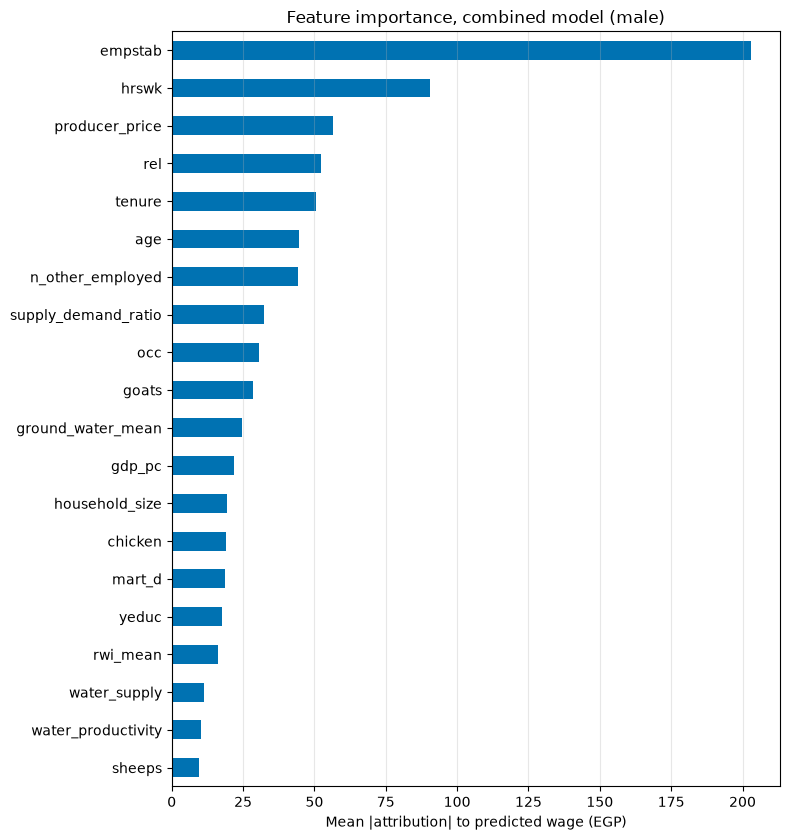

/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


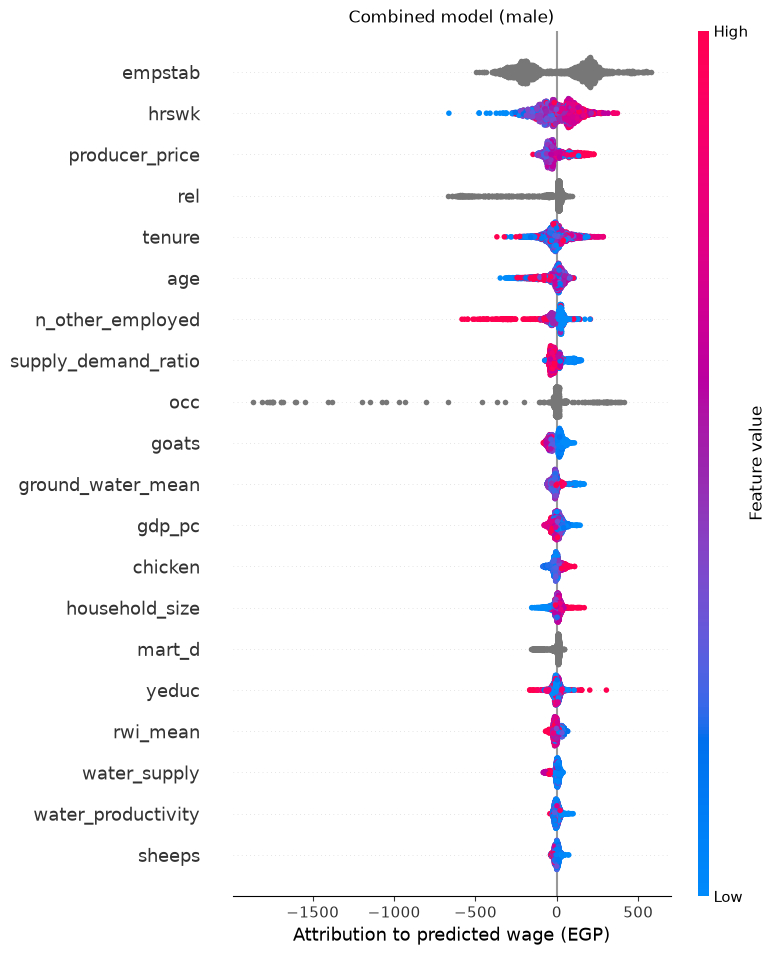

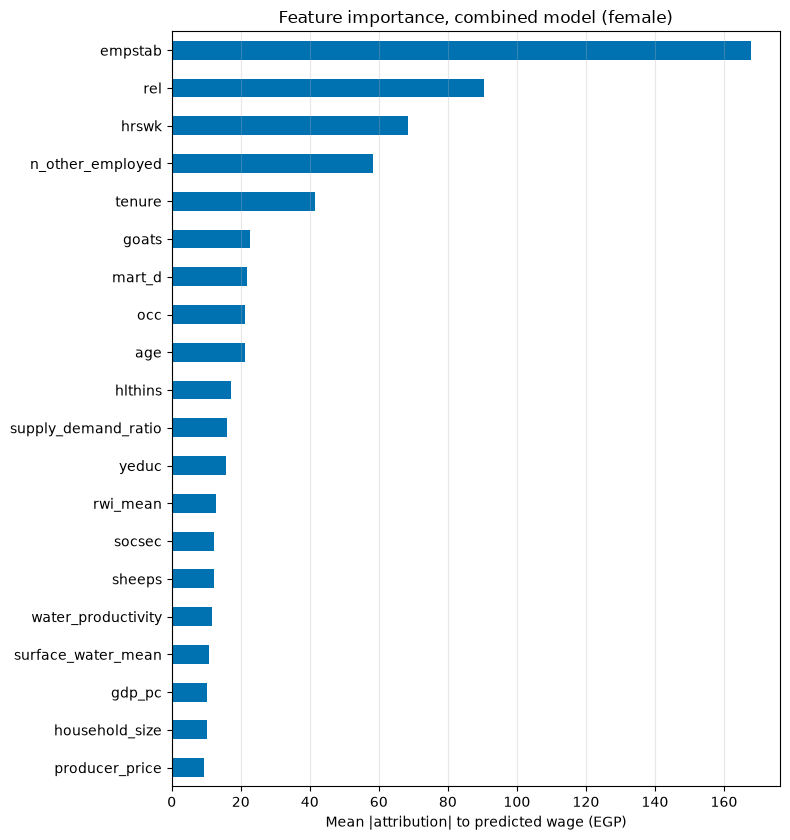

/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


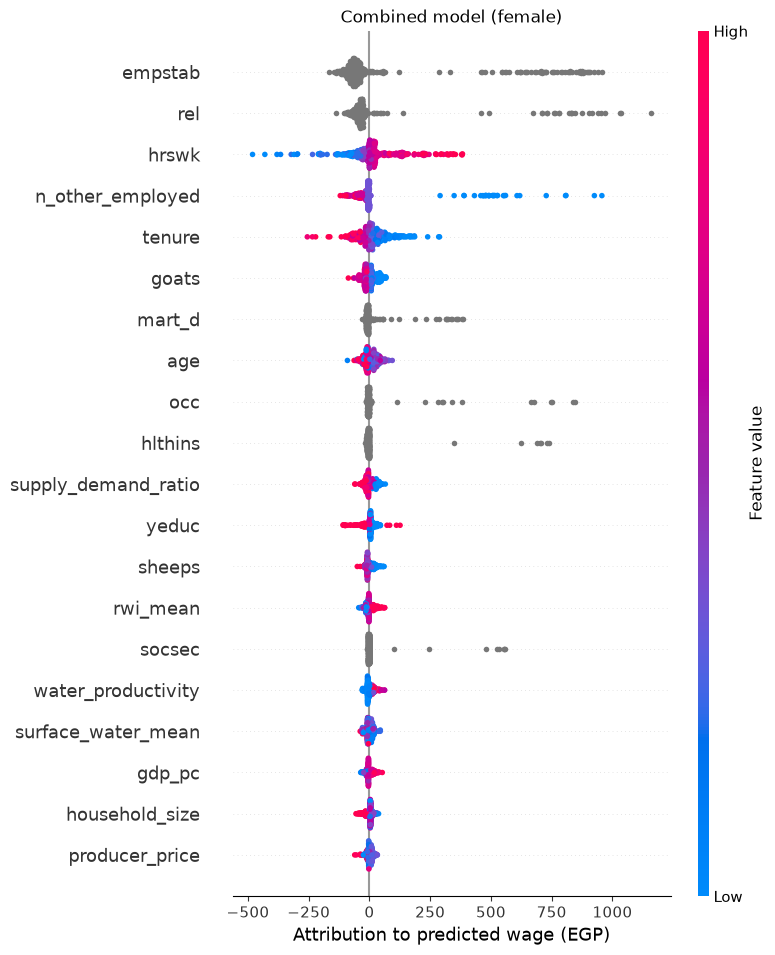

,male,female
empstab,202.987772,167.845420
hrswk,90.519491,68.463209
producer_price,56.563094,9.438725
rel,52.435423,90.522260
tenure,50.525141,41.518534
age,44.431292,21.247944
n_other_employed,44.330151,58.420386
supply_demand_ratio,32.483930,16.079293
occ,30.720345,21.318062
goats,28.305657,22.553031


In [15]:
# Feature importance of the combined model (classifier x regressor, all draws): SHAP values of both models are
# converted to EGP, combined so they add up to P(paid) * wage, and averaged over the ensemble members.
# Takes roughly 12 minutes for both sexes (SHAP for every member).
from egypt_survey_ml.explain import combined_shap, plot_importance, plot_beeswarm

FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

shap_male = combined_shap(ds, male_members, 'male')
shap_female = combined_shap(ds, female_members, 'female')

importance = pd.DataFrame({
    'male': shap_male.importance(weighted=True),
    'female': shap_female.importance(weighted=True),
}).sort_values('male', ascending=False)

for sex, res in [('male', shap_male), ('female', shap_female)]:
    plot_importance(res.importance(weighted=True), top=20, title=f'Feature importance, combined model ({sex})')
    plt.savefig(FIGURE_DIR / f'shap-importance-combined-{sex}.png')
    plt.show()

    # beeswarm: x = effect on the predicted wage (EGP), colour = feature value (grey = categorical)
    plot_beeswarm(res, top=20, title=f'Combined model ({sex})', show=False)
    plt.savefig(FIGURE_DIR / f'shap-beeswarm-combined-{sex}.png', bbox_inches='tight')
    plt.show()

importance

In [19]:
wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/wages_predictions_upper.csv")
nonzero_wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/nonzero_wages_predictions_upper.csv")

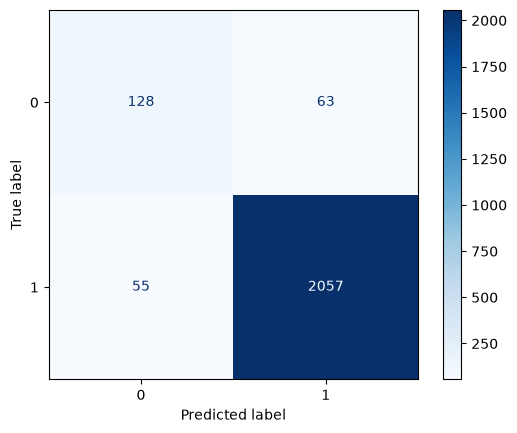

In [16]:
prediction_paid_male = pred_male.predicted_paid(threshold=0.70)
prediction_final_male = pred_male.final_wage()
true_paid_male = pred_male.true_paid
true_income_male = pred_male.true_income

y_pred = prediction_paid_male.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

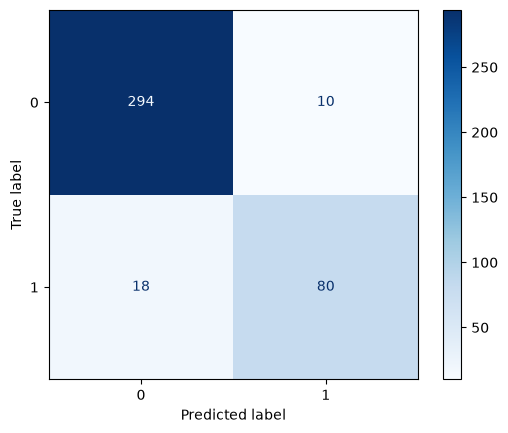

In [17]:
prediction_paid_female = pred_female.predicted_paid(threshold=0.33)
prediction_final_female = pred_female.final_wage()
true_paid_female = pred_female.true_paid
true_income_female = pred_female.true_income

y_pred = prediction_paid_female.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

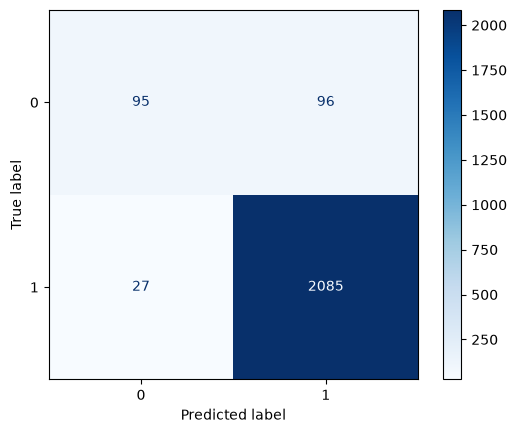

In [18]:
prediction_paid_male_nr = pred_male_nr.predicted_paid()
prediction_final_male_nr = pred_male_nr.final_wage()

y_pred = prediction_paid_male_nr.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

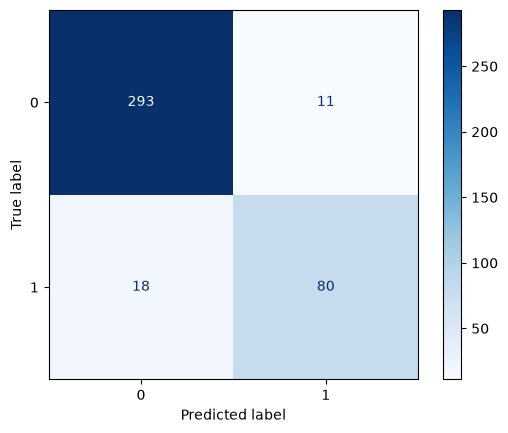

In [19]:
prediction_paid_female_nr = pred_female_nr.predicted_paid(threshold=0.33)
prediction_final_female_nr = pred_female_nr.final_wage()

y_pred = prediction_paid_female_nr.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

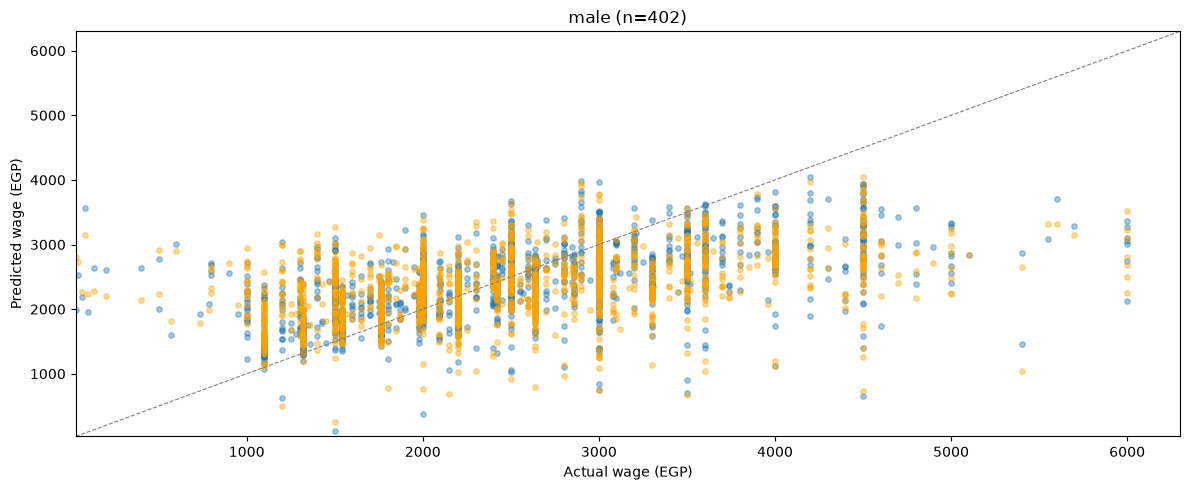

{'n': 2112, 'mae': 492.51337303529283, 'r2': 0.3409663646224297, 'spearman': np.float64(0.6289127174956083)}


In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

ax.scatter(y_true_male, y_pred_male, alpha=0.4, s=15)
ax.scatter(y_true_male, y_pred_nr_male, alpha=0.4, s=15, color='orange')
lims = [0.95 * min(y_true_male.min(), y_pred_male.min()), max(y_true_male.max(), y_pred_male.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"male (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_male),
    "mae": mean_absolute_error(y_true_male, y_pred_male),
    "r2": r2_score(y_true_male, y_pred_male),
    "spearman": sstats.spearmanr(y_true_male, y_pred_male).correlation,
}
print(metrics)

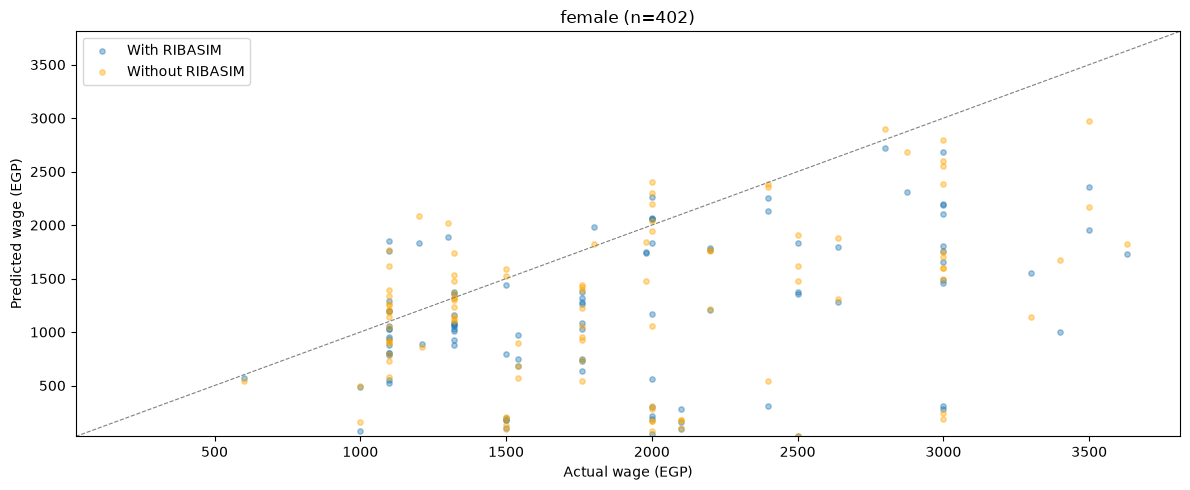

{'n': 98, 'mae': 795.660524689038, 'r2': -1.0856729934662672, 'spearman': np.float64(0.3796786213813294)}
{'n': 98, 'mae': 747.76866085625, 'r2': -0.9873848392178302, 'spearman': np.float64(0.3584657714033742)}


In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

ax.scatter(y_true_female, y_pred_female, alpha=0.4, s=15, label='With RIBASIM')
ax.scatter(y_true_female, y_pred_nr_female, alpha=0.4, s=15, color='orange', label='Without RIBASIM')
lims = [0.95 * min(y_true_female.min(), y_pred_female.min()), max(y_true_female.max(), y_pred_female.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"female (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
ax.legend()
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_female),
    "r2": r2_score(y_true_female, y_pred_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_female).correlation,
}
metrics_nr = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_nr_female),
    "r2": r2_score(y_true_female, y_pred_nr_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_nr_female).correlation,
}
print(metrics)
print(metrics_nr)

In [23]:
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

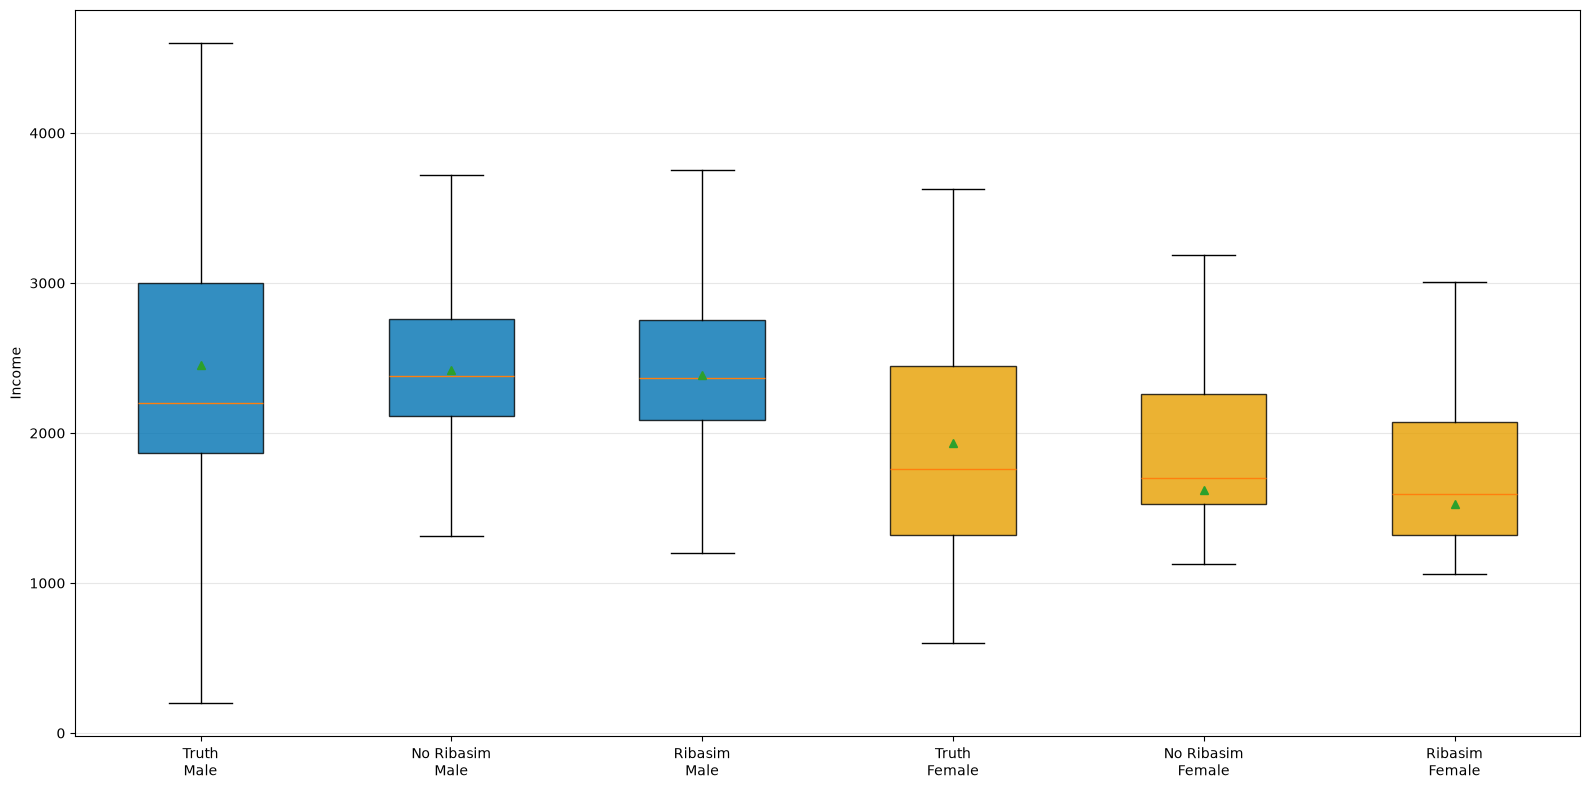

<Figure size 640x480 with 0 Axes>

In [65]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

labels = [
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
]

bp = ax.boxplot(
    data,
    patch_artist=True,
    showmeans=True,
    showfliers=False,
)

colors = [
    "#0072B2", "#0072B2",
    "#0072B2", "#E69F00",
    "#E69F00", "#E69F00",
]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_xticklabels(labels)

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(FIGURE_DIR / 'baseline-box-plots-with-hrs-22.png')

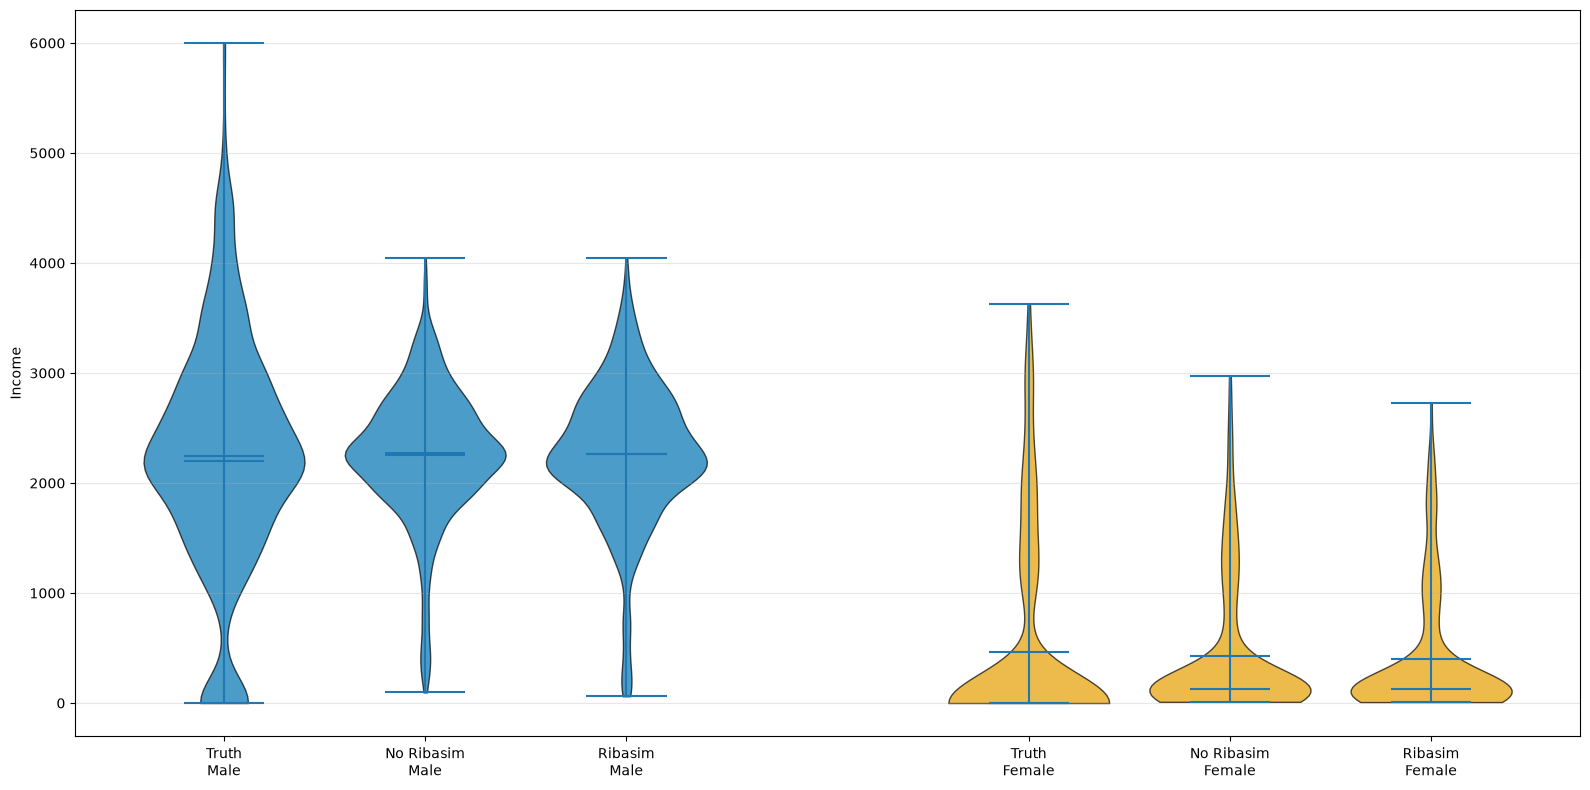

In [24]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

positions = [1, 2, 3, 5, 6, 7]

vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.8,
    showmeans=True,
    showmedians=True,
)

colors = [
    "#0072B2", "#0072B2",  # Truth
    "#0072B2", "#E69F00",  # Ribasim
    "#E69F00", "#E69F00",  # No Ribasim
]

for body, color in zip(vp["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.7)

ax.set_xticks(positions)
ax.set_xticklabels([
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
])

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
# plt.show()
plt.savefig(FIGURE_DIR / 'baseline-violin-plots-with-hrs-22.png')